# Axolotl telencephalon: development and regeneration

Compare six developmental and eight regeneration/control samples using WNT, BMP and FGF channels.

Training is commented out by default. **Run All** uses saved CellSTIC results and recomputes the analyses below. Figures and tables are saved alongside the existing model results under `DATA / "cellstic/time"`, grouped by analysis category. Run All does not train or modify the saved model.

## 1. Set up the dataset

Start Jupyter from this repository. Use the environment in `environment.yml` and supply the assembled inputs and saved results at the paths below.

In [1]:
from pathlib import Path
import sys
import json
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline/cellstic.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from pipeline.analysis import Analysis
from utils.analysis.result_io import load_result, lr_matrices, channel_keys
from utils.analysis import dataset_analysis as da
%matplotlib inline
plt.style.use("default")
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

<conda-env>/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA = ROOT / "paper/data/axolotl_tele"
RUN_ROOT = DATA / "cellstic"
OUTPUT = RUN_ROOT / "time"
OUTPUT.mkdir(parents=True, exist_ok=True)
from utils.analysis.time_series import TimeSeriesAnalysis

In [3]:
DEVELOPMENT = ["dev_44", "dev_54", "dev_57", "dev_Juvenile", "dev_Adult", "dev_meta"]
REGENERATION = ["reg_2", "reg_5", "reg_10", "reg_15", "reg_20", "reg_30", "reg_60", "reg_control"]
SAMPLES = DEVELOPMENT + REGENERATION

## 2. Train each sample (optional)

Uncomment both cells to fit each assembled RNA sample independently with the same dataset preset. All trained samples then become the inputs to the time-series analysis.

In [4]:
# from model.train import get_cellstic_config
# from pipeline.cellstic import run_cellstic
# config = get_cellstic_config('axolotl_telencephalon')

In [5]:
# for sample in SAMPLES:
#     rna = ad.read_h5ad(DATA / "h5ad" / f"{sample}.h5ad")
#     lr_map = {name: list(values) for name, values in rna.uns["ligand_receptor_map"].items()}
#     run_cellstic([rna], config, modality_types=["rna"], ligand_receptor_map=lr_map,
#                  output_path=RUN_ROOT / sample)


## 3. Build the ordered sample table

Each row is one independently fitted sample. Stage positions on plots are categorical; they do not imply equal biological time intervals. The uninjured control is labeled Ctrl and displayed as a separate reference category; it is not a later regeneration day.

In [6]:
samples = pd.DataFrame([dict(sample=s, stage=s.split("_", 1)[1],
                             group="Development" if s in DEVELOPMENT else "Regeneration",
                             control=s == "reg_control", path=RUN_ROOT / s / "out/out.h5ad") for s in SAMPLES])
series = TimeSeriesAnalysis(samples, annotation_key="Annotation")
tables = series.summarize(selected_pairs={"Development": "WNT7B:FZD5", "Regeneration": "WNT7B:FZD5"})
display(tables["samples"])

,sample,stage,group,control,observations
0,dev_44,44,Development,False,1477
1,dev_54,54,Development,False,2929
2,dev_57,57,Development,False,4410
3,dev_Juvenile,Juvenile,Development,False,11698
4,dev_Adult,Adult,Development,False,8243
5,dev_meta,meta,Development,False,7441
6,reg_2,2,Regeneration,False,7668
7,reg_5,5,Regeneration,False,8106
8,reg_10,10,Regeneration,False,9440
9,reg_15,15,Regeneration,False,9676


## 4. Compare ligand–receptor edge counts

WNT7B–FZD5 is displayed across development and regeneration; the table retains all four fitted LR channels. Counts include all positive stored leaf edges. Differences also depend on tissue coverage and fitting.

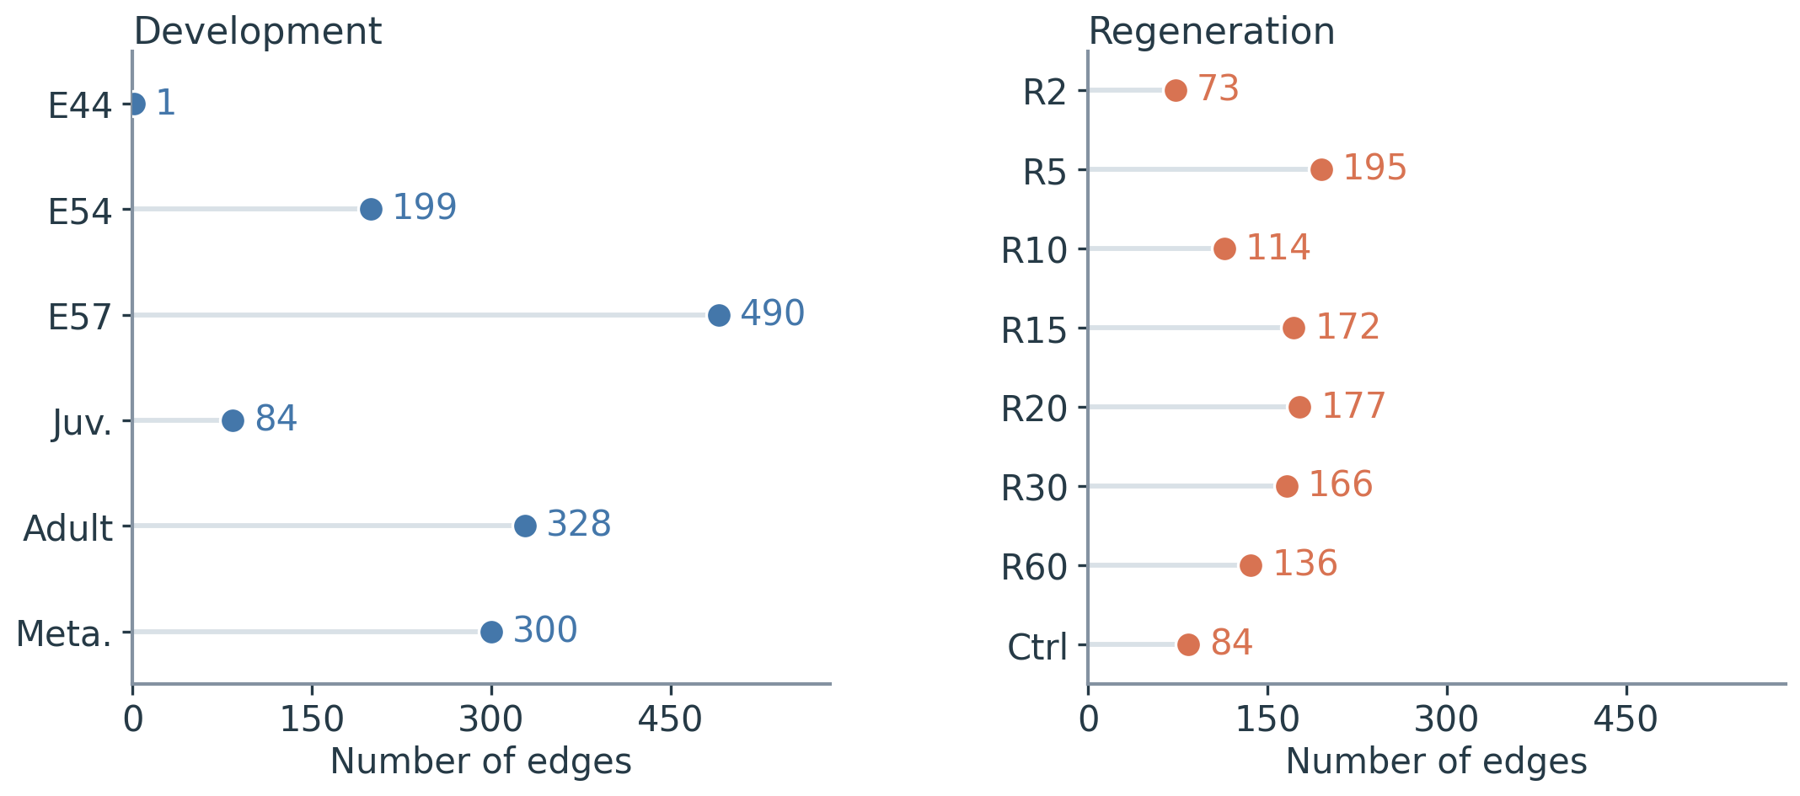

In [7]:
from utils.analysis import temporal_visualization as tv
tv.time_lr_counts(series, OUTPUT / "lr_counts")

## 5. Follow cell-type communication strength

Sum outgoing plus incoming strength over all LR channels. Each edge contributes at both endpoints. The plot retains the ten strongest cell types per series and groups the rest as Other. The exported table also reports cell counts and mean strength per cell.

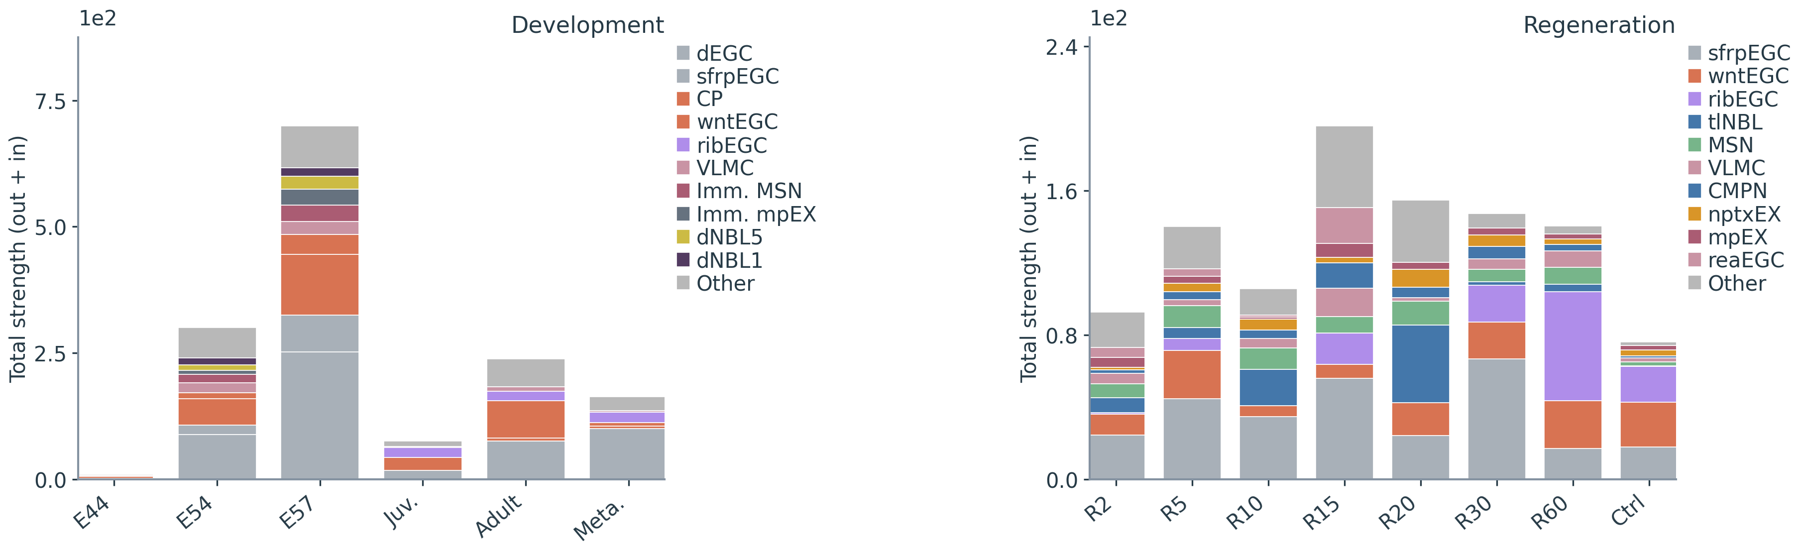

In [8]:
tv.time_celltypes(series, OUTPUT / "celltype_strength")

## 6. Compare global efficiency, path length and modularity

Recompute these descriptors from the sum of all retained LR channels. Remove
self edges and use the larger reciprocal weight to form an undirected graph.
Global efficiency is the mean reciprocal **unweighted** shortest-path length
over all distinct node pairs, with zero contribution from unreachable pairs.
Mean path length uses reachable pairs only. Modularity uses weighted Louvain
communities (resolution 1, seed 42). Isolated observations are retained.

These definitions apply to the saved CCC graphs; the plots do not reuse archived
figure constants. The uninjured regeneration control is a horizontal reference.
Graph scores and coverage vary between samples.

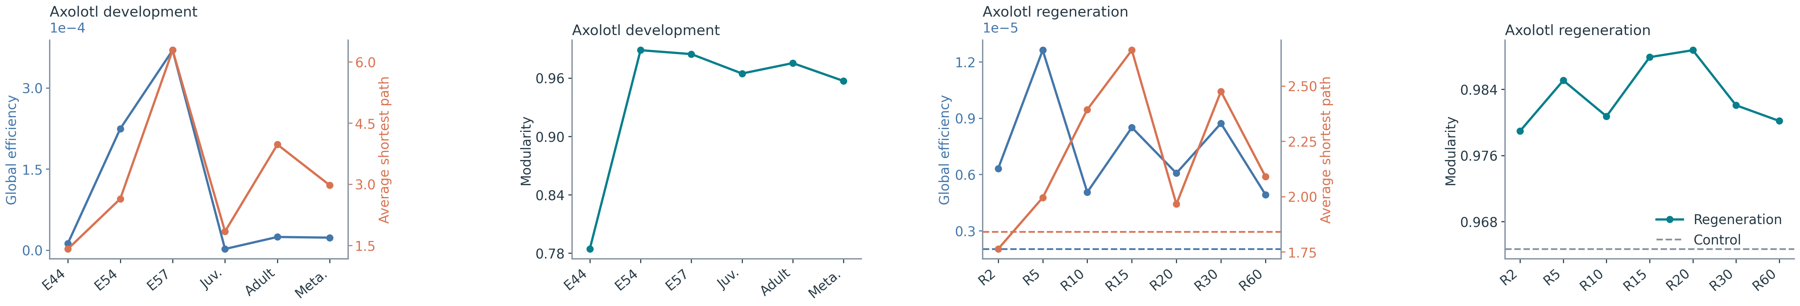

In [9]:
network_summary = series.summarize_networks()
tv.time_network_metrics(series, OUTPUT / "network_metrics")
series.export(OUTPUT)